In [2]:
from sklearn.datasets import load_iris
iris= load_iris()

In [3]:
import pandas as pd
df=pd.DataFrame(iris.data, columns=iris.feature_names)

In [4]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [5]:
df['target']=iris.target
df['species']=df['target'].apply(lambda x: iris.target_names[x])

In [6]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [7]:
df.shape

(150, 6)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 8.4 KB


In [9]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

In [10]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

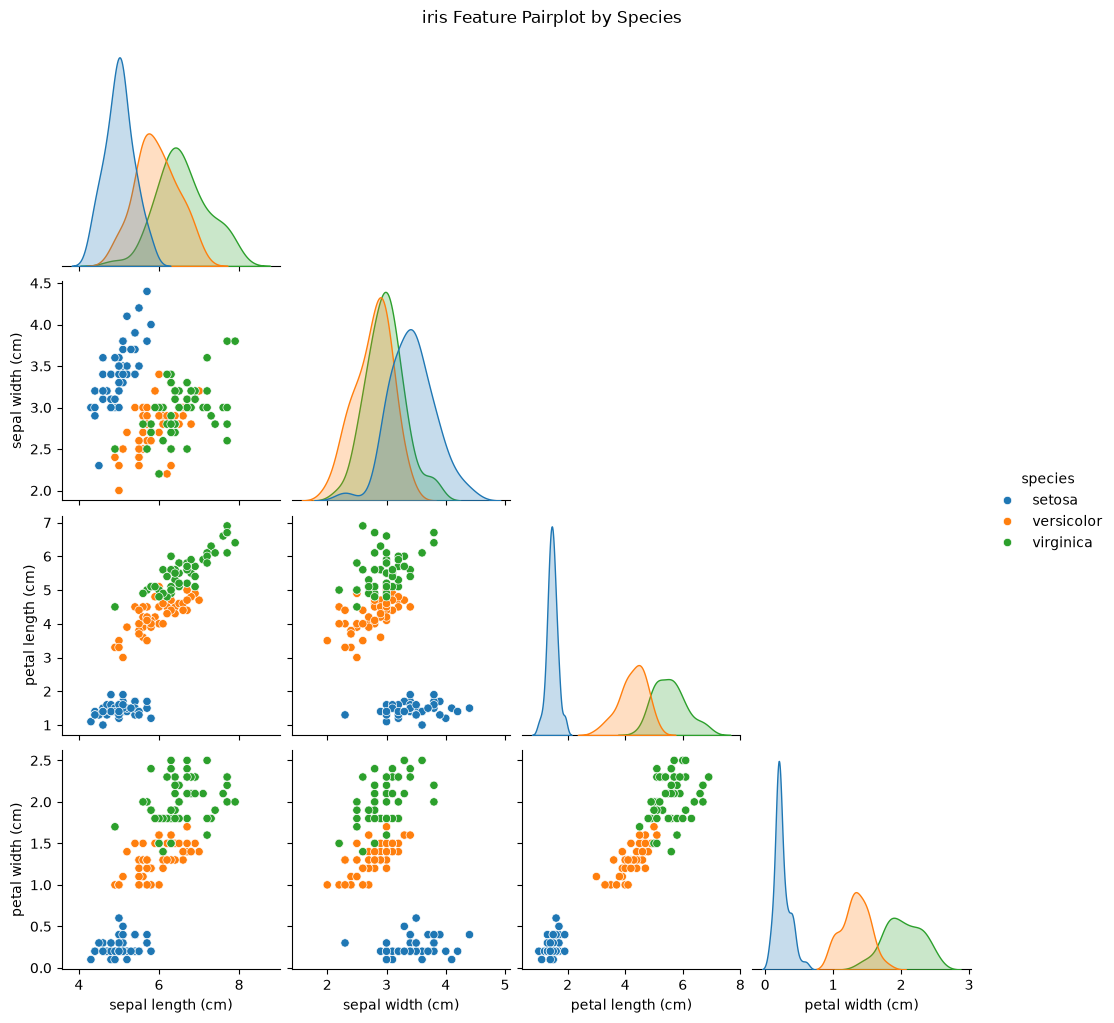

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.pairplot(df, hue='species', vars=iris.feature_names, corner=True)
plt.suptitle("iris Feature Pairplot by Species", y=1.02)
plt.show()

In [12]:
import numpy as np
from sklearn.model_selection import train_test_split


In [13]:
X = df.drop(columns=['target','species'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,       # Allocates 20% to the test set
    random_state=42,     # Ensures reproducible splits
    stratify=y           # Balances species ratios in both train & test sets
)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape:  {X_test.shape}")


Training features shape: (120, 4)
Testing features shape:  (30, 4)


In [14]:
X_train.head()
y_train.head()

8      0
106    2
76     1
9      0
89     1
Name: target, dtype: int64

In [15]:
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
%matplotlib inline
sns.set_style('whitegrid')

In [16]:
train_correlation = X_train.corr()

print(train_correlation.round(2))


                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)               1.00             -0.11               0.88   
sepal width (cm)               -0.11              1.00              -0.40   
petal length (cm)               0.88             -0.40               1.00   
petal width (cm)                0.82             -0.34               0.96   

                   petal width (cm)  
sepal length (cm)              0.82  
sepal width (cm)              -0.34  
petal length (cm)              0.96  
petal width (cm)               1.00  


In [17]:
train_covariance = X_train.cov()
print(train_covariance.round(3))


                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)              0.707            -0.042              1.309   
sepal width (cm)              -0.042             0.201             -0.316   
petal length (cm)              1.309            -0.316              3.128   
petal width (cm)               0.526            -0.116              1.300   

                   petal width (cm)  
sepal length (cm)             0.526  
sepal width (cm)             -0.116  
petal length (cm)             1.300  
petal width (cm)              0.582  


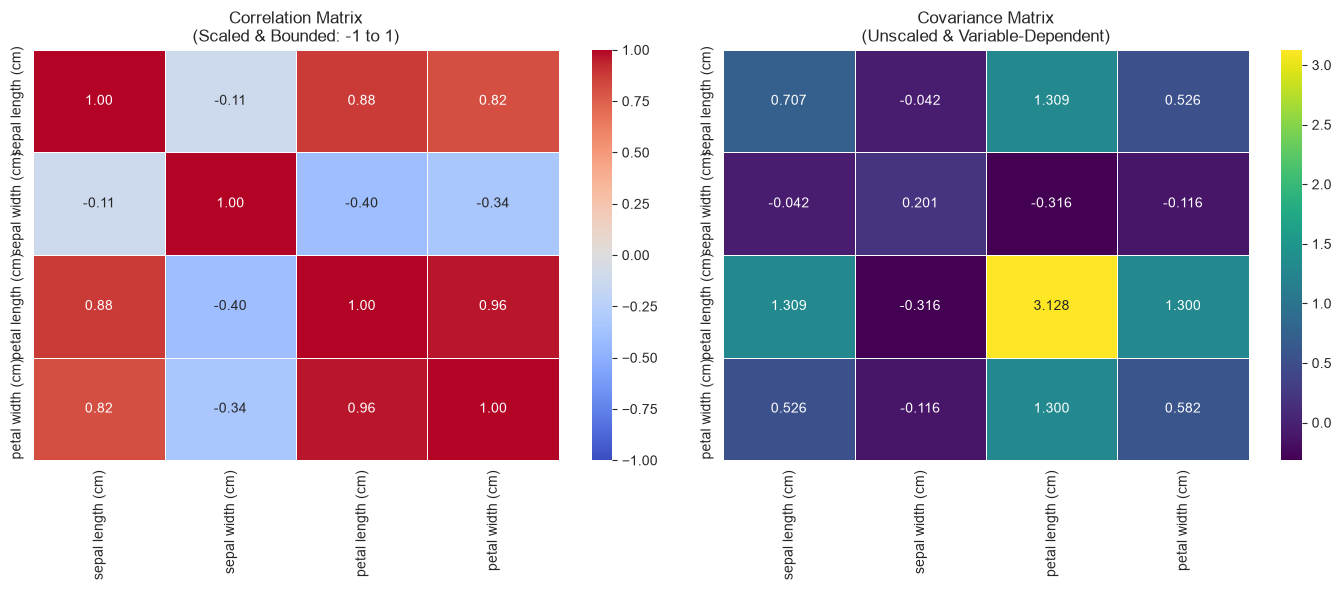

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(
    X_train.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=axes[0],
)
axes[0].set_title("Correlation Matrix\n(Scaled & Bounded: -1 to 1)")
sns.heatmap(
    X_train.cov(),
    annot=True,
    cmap="viridis",
    fmt=".3f",
    linewidths=0.5,
    ax=axes[1],
)
axes[1].set_title("Covariance Matrix\n(Unscaled & Variable-Dependent)")

plt.tight_layout()
plt.show()


Training Accuracy: 98.33%
Testing Accuracy:  96.67%


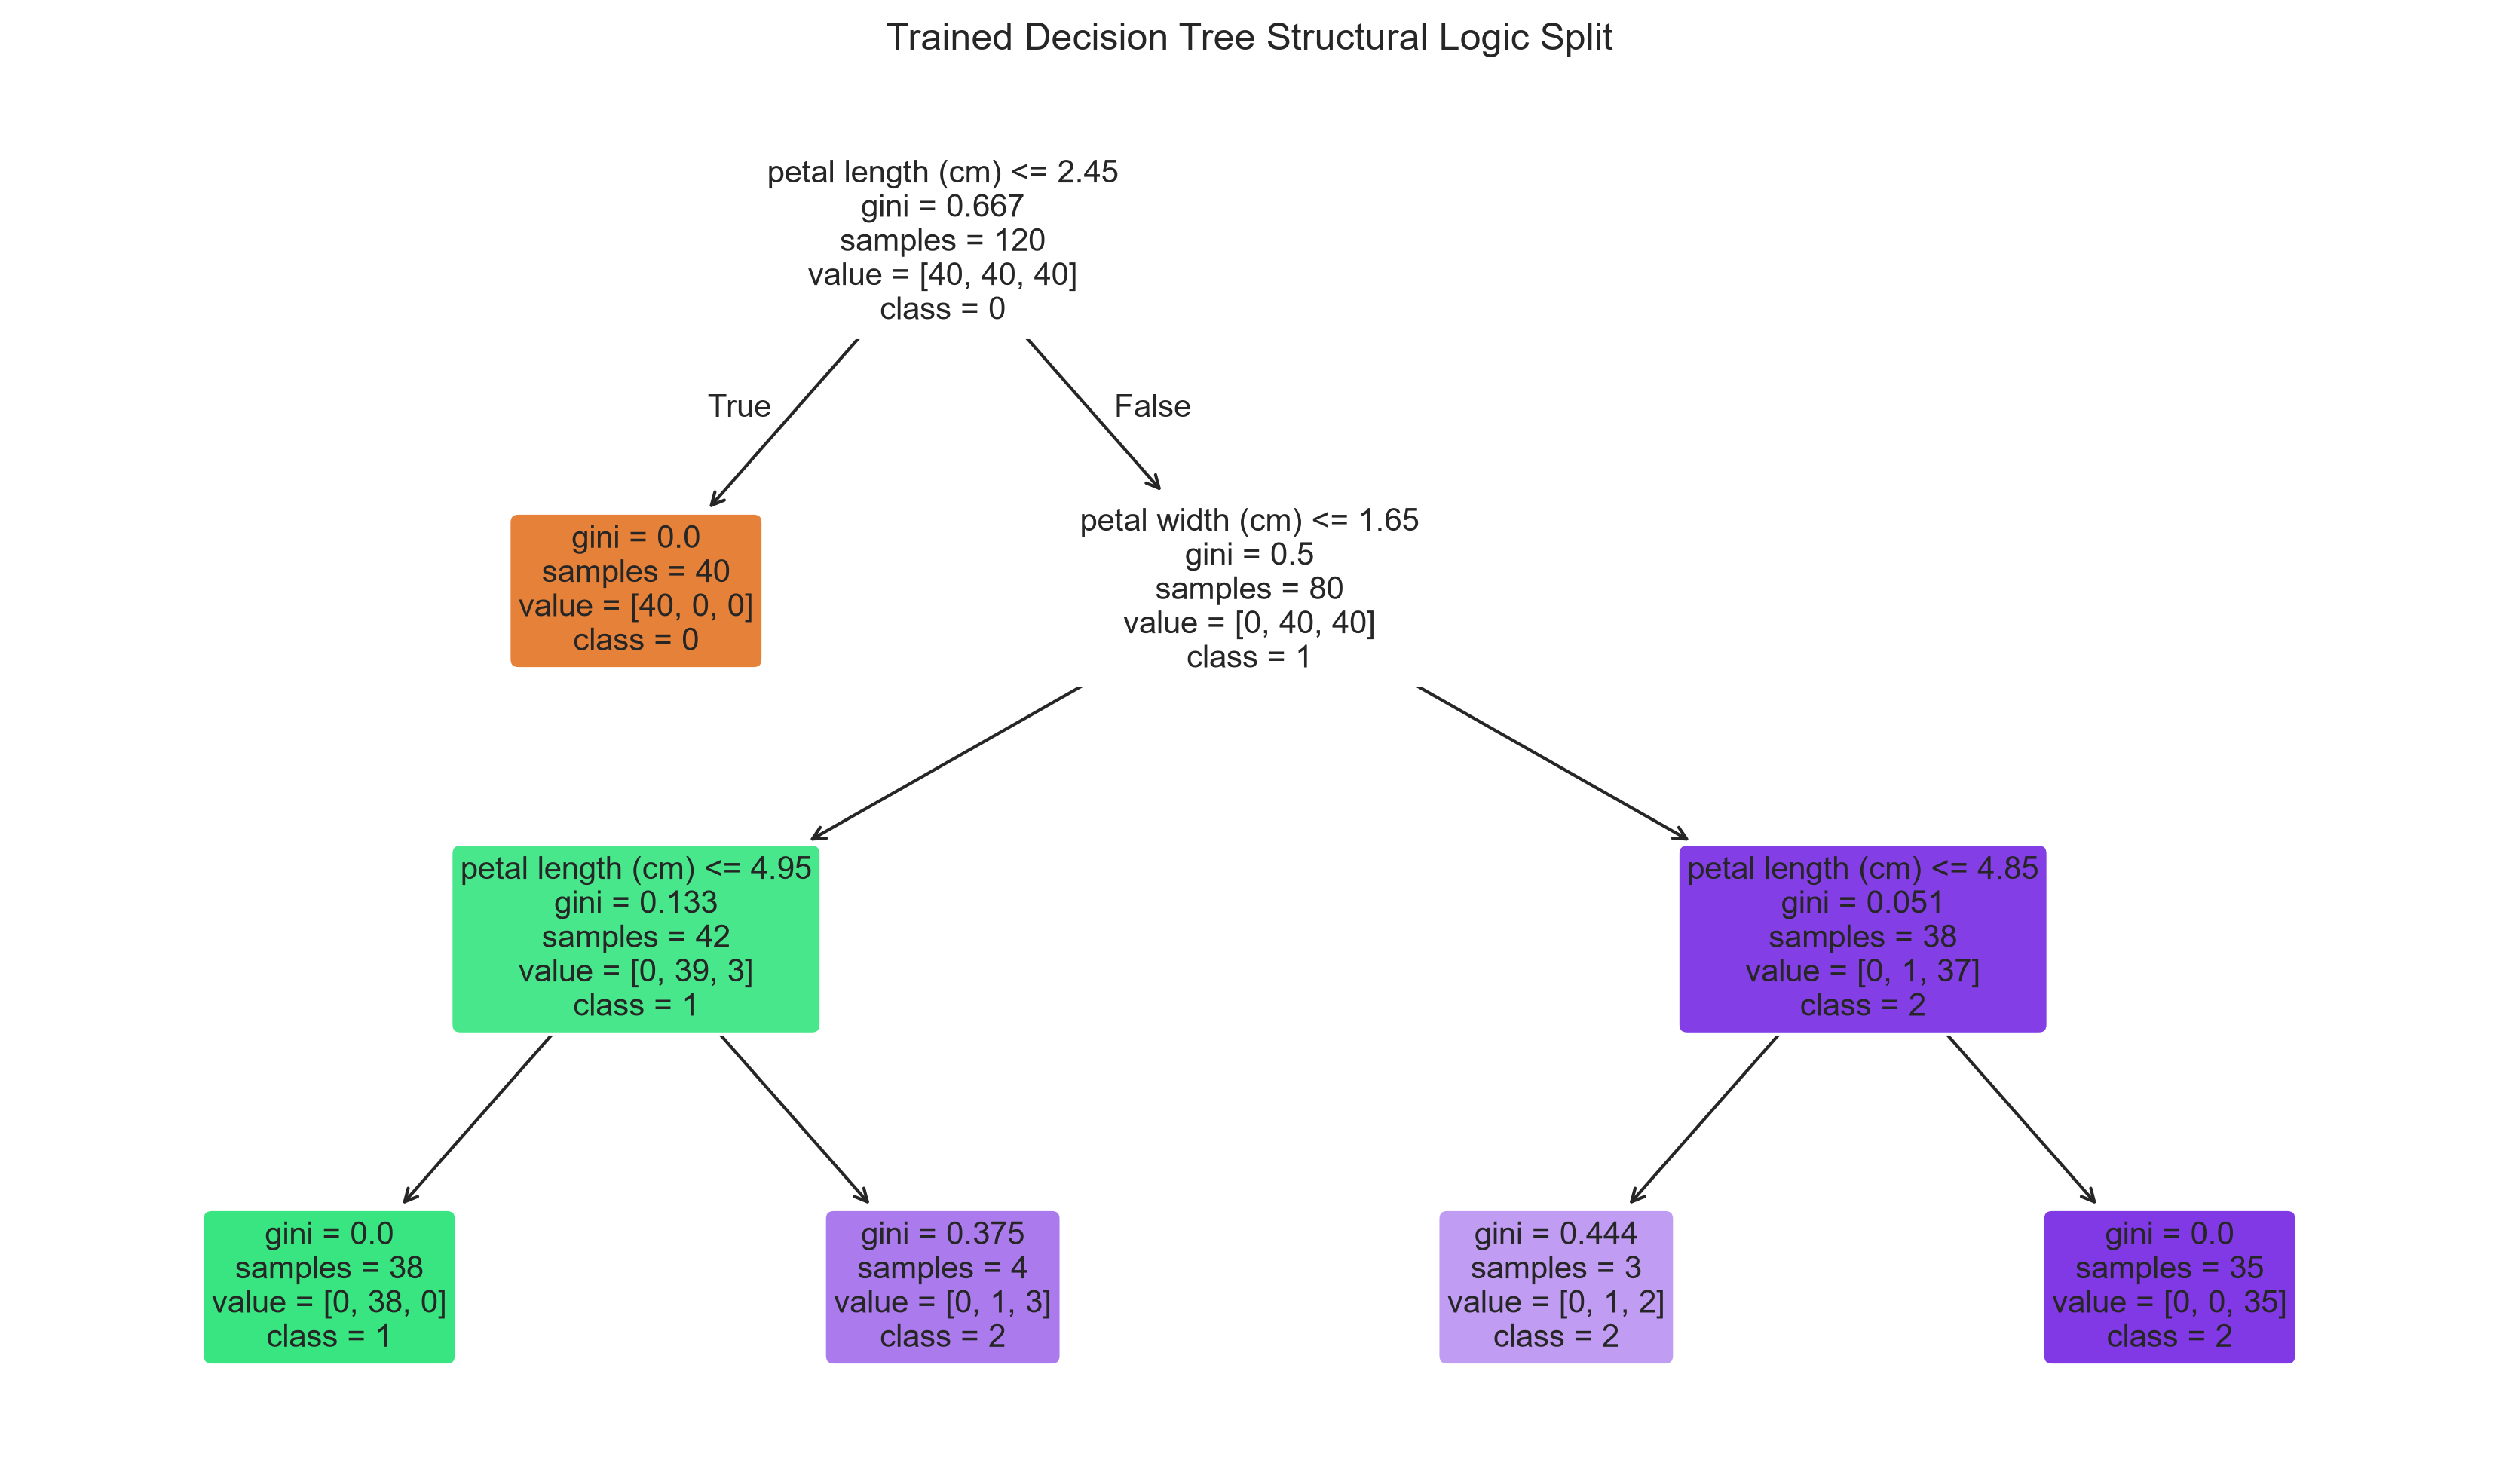

In [19]:
# 1. Initialize the Decision Tree Classifier
# We set a max_depth to prevent overfitting and random_state for reproducibility
dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)

# 2. Train the model using the training partitions
dt_model.fit(X_train, y_train)

# 3. Print the training baseline accuracy
train_acc = dt_model.score(X_train, y_train)
test_acc = dt_model.score(X_test, y_test)
print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy:  {test_acc * 100:.2f}%")

# 4. Generate the graphical representation of the trained tree rules
plt.figure(figsize=(14, 8), dpi=300)
plot_tree(
    dt_model,
    feature_names=X_train.columns,
    class_names=dt_model.classes_.astype(str),
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Trained Decision Tree Structural Logic Split")
plt.show()


               TRAINING SET PERFORMANCE REPORT               
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      0.95      0.97        40
           2       0.95      1.00      0.98        40

    accuracy                           0.98       120
   macro avg       0.98      0.98      0.98       120
weighted avg       0.98      0.98      0.98       120

                 TEST SET PERFORMANCE REPORT                 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



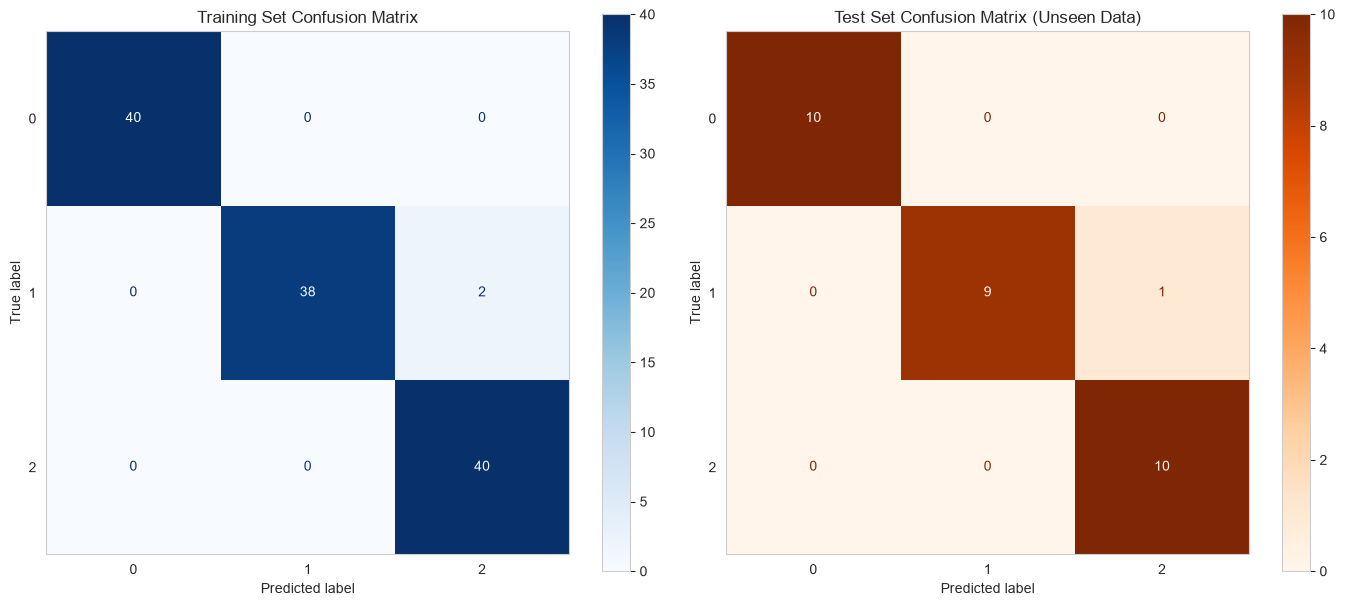

C:\Users\Hp\AppData\Local\Temp\ipykernel_16716\4050553455.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=features_ranked, palette="viridis")


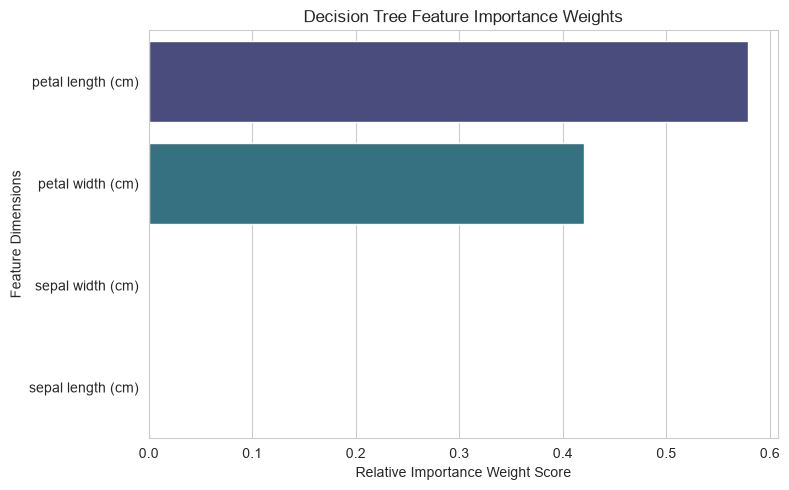

In [20]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)

# 1. Generate model predictions for both subsets
y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

# 2. Extract unique target classes as text strings
class_names = [str(cls) for cls in dt_model.classes_]

# 3. Print Comprehensive Performance Metrics Reports
print("=" * 60)
print("               TRAINING SET PERFORMANCE REPORT               ")
print("=" * 60)
print(classification_report(y_train, y_train_pred, target_names=class_names))

print("=" * 60)
print("                 TEST SET PERFORMANCE REPORT                 ")
print("=" * 60)
print(classification_report(y_test, y_test_pred, target_names=class_names))

# 4. Generate Graphical Evaluation (Confusion Matrices Side-by-Side)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left Subplot: Training Set Confusion Matrix
cm_train = confusion_matrix(y_train, y_train_pred)
disp_train = ConfusionMatrixDisplay(
    confusion_matrix=cm_train, display_labels=class_names
)
disp_train.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Training Set Confusion Matrix")
axes[0].grid(False)

# Right Subplot: Testing Set Confusion Matrix
cm_test = confusion_matrix(y_test, y_test_pred)
disp_test = ConfusionMatrixDisplay(
    confusion_matrix=cm_test, display_labels=class_names
)
disp_test.plot(ax=axes[1], cmap="Oranges", values_format="d")
axes[1].set_title("Test Set Confusion Matrix (Unseen Data)")
axes[1].grid(False)

plt.tight_layout()
plt.show()

# 5. Graphical Feature Importances Breakdown
plt.figure(figsize=(8, 5))
importances = dt_model.feature_importances_
indices = np.argsort(importances)[::-1]
features_ranked = [X_train.columns[i] for i in indices]

sns.barplot(x=importances[indices], y=features_ranked, palette="viridis")
plt.title("Decision Tree Feature Importance Weights")
plt.xlabel("Relative Importance Weight Score")
plt.ylabel("Feature Dimensions")
plt.tight_layout()
plt.show()


In [23]:
import joblib

joblib.dump(dt_model, 'iris_classification_model.joblib')


['iris_classification_model.joblib']